<a href="https://colab.research.google.com/github/AsmaaaSalis/agriprice-teller-intelligence/blob/main/04_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 4: Forecasting

Forecasting monthly retail prices (NGN per kg) of millet, rice (local) and groundnuts in
Borno and Yobe, 1 to 3 months ahead. Comparing simple baselines (naive, seasonal naive)
with a statistical model (SARIMA) and a machine learning model (XGBoost) using
rolling-origin testing, where each model is refit and tested again at each point in time,
using only past data. Forecasts are scored only on months with a real (not interpolated)
price, and accuracy is reported separately before and after mid-2023.
The notebook ends with a forecast for the three months after the last observed month.

Input: clean_monthly_prices.csv (from Notebook 2).

In [1]:
# Importing libraries

import warnings
import pandas as pd                                     # Data tables
import numpy as np                                      # Missing values and maths
import matplotlib.pyplot as plt                         # Charts
from statsmodels.tsa.statespace.sarimax import SARIMAX  # SARIMA model
from xgboost import XGBRegressor                        # XGBoost model

# Setting display options and hiding routine model warnings
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 100)
warnings.filterwarnings('ignore')

print('Libraries loaded')

Libraries loaded


### 1. Loading the clean data and setting the test parameters

In [2]:
# Loading the clean monthly dataset (output of Notebook 2)
df = pd.read_csv('clean_monthly_prices.csv', parse_dates=['date'])

# Keeping data from January 2017 (the common modelling start)
df = df[df['date'] >= '2017-01-01'].copy()

# Checking the size of the table (rows, columns)
print(df.shape)
df.head()

(708, 6)


,date,state,commodity,price_per_kg_ngn,n_markets,is_interpolated
12,2017-01-01,Borno,Groundnuts,350.000000,9,False
13,2017-02-01,Borno,Groundnuts,340.909091,9,False
14,2017-03-01,Borno,Groundnuts,363.636364,9,False
15,2017-04-01,Borno,Groundnuts,386.363636,9,False
16,2017-05-01,Borno,Groundnuts,370.000000,9,False


In [3]:
# Setting the forecast test parameters
HORIZONS = [1, 2, 3]                  # Months ahead to forecast
FIRST_ORIGIN = '2020-01-01'           # First forecast origin (3 years of history before it)
BREAK = pd.Timestamp('2023-06-01')    # Mid-2023: fuel subsidy removal and naira unification

print('Settings saved')

Settings saved


In [4]:
# Building one price series per state and crop
series = {}      # All prices (used to fit models)
observed = {}    # Real prices only (used to score forecasts)

for (state, crop), g in df.groupby(['state', 'commodity']):
    g = g.sort_values('date').set_index('date')
    series[(state, crop)] = g['price_per_kg_ngn']
    observed[(state, crop)] = g['price_per_kg_ngn'].where(~g['is_interpolated'])

print(len(series), 'series built')
print(list(series.keys()))

6 series built
[('Borno', 'Groundnuts'), ('Borno', 'Millet'), ('Borno', 'Rice (local)'), ('Yobe', 'Groundnuts'), ('Yobe', 'Millet'), ('Yobe', 'Rice (local)')]


### 2. Baselines
Naive repeats the latest price; seasonal naive repeats the price from the same month last year.

In [5]:
# Building rolling-origin forecasts for the two baselines
records = []

for key in series:
    price = series[key]
    obs = observed[key]
    dates = price.index
    # Forecast origins: from the first origin to one month before the last date
    origins = dates[(dates >= FIRST_ORIGIN) & (dates <= dates[-1] - pd.DateOffset(months=1))]

    for origin in origins:
        # Using only data up to the origin
        history = price.loc[:origin].dropna()
        if history.empty:
            continue
        last_price = history.iloc[-1]                    # Naive forecast

        for h in HORIZONS:
            target = origin + pd.DateOffset(months=h)
            # Scoring only months with a real (not interpolated) price
            if target not in dates or pd.isna(obs.loc[target]):
                continue
            # Seasonal naive: same month last year (falls back to naive if missing)
            last_year = target - pd.DateOffset(months=12)
            seasonal = price.get(last_year, np.nan)
            fallback = pd.isna(seasonal)
            if fallback:
                seasonal = last_price
            records.append({'state': key[0], 'commodity': key[1], 'origin': origin,
                            'target': target, 'h': h, 'actual': obs.loc[target],
                            'naive': last_price, 'seasonal_naive': seasonal,
                            'sn_fallback': fallback})

forecasts = pd.DataFrame(records)
print(forecasts.shape)
print('Seasonal naive fallbacks:', int(forecasts['sn_fallback'].sum()))
print(forecasts.groupby('h').size())

(1245, 9)
Seasonal naive fallbacks: 135
h
1    420
2    414
3    411
dtype: int64


### 3. SARIMA
Fitted on log prices at every origin using only past data. Takes several minutes: wait for it to finish.

In [6]:
# Fitting SARIMA at each origin and forecasting up to 3 months ahead
sarima_preds = {}

for key in series:
    price = series[key]
    dates = price.index
    origins = dates[(dates >= FIRST_ORIGIN) & (dates <= dates[-1] - pd.DateOffset(months=1))]

    for origin in origins:
        # Using only data up to the origin, on log prices
        history_log = np.log(price.loc[:origin])
        try:
            model = SARIMAX(history_log, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12),
                            enforce_stationarity=True, enforce_invertibility=True)
            fit = model.fit(disp=False, maxiter=100)
            f = np.exp(fit.forecast(max(HORIZONS)).values)
        except Exception:
            f = np.full(max(HORIZONS), np.nan)
        for h in HORIZONS:
            sarima_preds[(key[0], key[1], origin, h)] = f[h - 1]

# Adding SARIMA forecasts to the forecast table
forecasts['sarima'] = [sarima_preds.get((s, c, o, h), np.nan)
                       for s, c, o, h in zip(forecasts['state'], forecasts['commodity'],
                                             forecasts['origin'], forecasts['h'])]

# Replacing failed or unstable forecasts with the naive value
bad = (forecasts['sarima'].isna()
       | (forecasts['sarima'] > 3 * forecasts['naive'])
       | (forecasts['sarima'] < forecasts['naive'] / 3))
print('SARIMA fallbacks to naive:', int(bad.sum()))
forecasts.loc[bad, 'sarima'] = forecasts.loc[bad, 'naive']

SARIMA fallbacks to naive: 0


In [7]:
# Saving the forecasts so they are not lost
forecasts.to_csv('forecasts_baselines_sarima.csv', index=False)
print(forecasts.shape)

(1245, 10)


### 4. XGBoost
A machine learning model that learns from a table of clues (features). The clues are relative, which avoids the problem of
post-2023 prices being far higher than anything earlier: recent price changes, price vs recent averages,
state and crop codes, and the calendar month being forecast. The model predicts the % change from the latest price.

In [8]:
# Coding states and crops as numbers
crop_code = {'Millet': 0, 'Rice (local)': 1, 'Groundnuts': 2}
state_code = {'Borno': 0, 'Yobe': 1}

# Building the feature table, one series at a time
parts = []
for key, price in series.items():
    f = pd.DataFrame({'price': price})
    lp = np.log(price)
    # Price changes over the last 1, 2, 3 and 12 months
    f['chg_1m'] = lp - lp.shift(1)
    f['chg_2m'] = lp - lp.shift(2)
    f['chg_3m'] = lp - lp.shift(3)
    f['chg_12m'] = lp - lp.shift(12)
    # Price compared with its 3-month and 6-month average
    f['vs_avg3'] = lp - np.log(price.rolling(3, min_periods=2).mean())
    f['vs_avg6'] = lp - np.log(price.rolling(6, min_periods=4).mean())
    f['state'], f['commodity'] = key
    f['state_code'], f['crop_code'] = state_code[key[0]], crop_code[key[1]]
    f['obs'] = observed[key]          # Real prices only (used for the answers)
    parts.append(f)
feat = pd.concat(parts).rename_axis('date').reset_index()

FEATURES = ['chg_1m', 'chg_2m', 'chg_3m', 'chg_12m', 'vs_avg3', 'vs_avg6',
            'state_code', 'crop_code', 'target_month']

# Adding the answers: change from today's price to the real price h months later
for h in HORIZONS:
    feat[f'y{h}'] = np.nan
for (state, crop), sub in feat.groupby(['state', 'commodity']):
    sub = sub.sort_values('date')
    for h in HORIZONS:
        feat.loc[sub.index, f'y{h}'] = np.log(sub['obs'].shift(-h) / sub['price']).values

print(feat.shape)
feat.head()

(708, 16)


,date,price,chg_1m,chg_2m,chg_3m,chg_12m,vs_avg3,vs_avg6,state,commodity,state_code,crop_code,obs,y1,y2,y3
0,2017-01-01,350.000000,NaN,NaN,NaN,NaN,NaN,NaN,Borno,Groundnuts,0,2,350.000000,-0.026317,0.038221,0.098846
1,2017-02-01,340.909091,-0.026317,NaN,NaN,NaN,-0.013245,NaN,Borno,Groundnuts,0,2,340.909091,0.064539,0.125163,0.081887
2,2017-03-01,363.636364,0.064539,0.038221,NaN,NaN,0.033902,NaN,Borno,Groundnuts,0,2,363.636364,0.060625,0.017349,0.000000
3,2017-04-01,386.363636,0.060625,0.125163,0.098846,NaN,0.060625,0.070044,Borno,Groundnuts,0,2,386.363636,-0.043276,-0.060625,0.000000
4,2017-05-01,370.000000,-0.043276,0.017349,0.081887,NaN,-0.008969,0.021357,Borno,Groundnuts,0,2,370.000000,-0.017349,0.043276,0.644050


In [9]:
# Fitting XGBoost at each origin and horizon, using only past data
origins = sorted(forecasts['origin'].unique())
xgb_preds = {}
importances = {}

for origin in origins:
    for h in HORIZONS:
        tmp = feat.copy()
        tmp['target_month'] = (tmp['date'] + pd.DateOffset(months=h)).dt.month
        # Training rows: those whose target month is on or before the origin
        train = tmp[(tmp['date'] + pd.DateOffset(months=h) <= origin) & tmp[f'y{h}'].notna()]
        now = tmp[tmp['date'] == origin]
        if len(train) < 60 or now.empty:
            continue
        model = XGBRegressor(n_estimators=150, max_depth=3, learning_rate=0.05,
                             subsample=0.8, random_state=0, n_jobs=1)
        model.fit(train[FEATURES], train[f'y{h}'])
        change = model.predict(now[FEATURES])
        # Converting the predicted change back into a price
        for s, c, p, ch in zip(now['state'], now['commodity'], now['price'], change):
            xgb_preds[(s, c, origin, h)] = p * np.exp(ch)
        if origin == origins[-1] and h == 1:
            importances = dict(zip(FEATURES, model.feature_importances_))

# Adding XGBoost forecasts to the forecast table
forecasts['xgboost'] = [xgb_preds.get((s, c, o, h), np.nan)
                        for s, c, o, h in zip(forecasts['state'], forecasts['commodity'],
                                              forecasts['origin'], forecasts['h'])]

# Using the naive value where no forecast was possible
print('Forecasts without an XGBoost value:', int(forecasts['xgboost'].isna().sum()))
forecasts['xgboost'] = forecasts['xgboost'].fillna(forecasts['naive'])

Forecasts without an XGBoost value: 36


### 5. Accuracy
MAE: average miss in NGN per kg. RMSE: like MAE but big misses count extra.
MAPE: average miss as a % of the real price, so crops can be compared.

In [10]:
# Labelling each forecast as before or after mid-2023
forecasts['period'] = np.where(forecasts['target'] < BREAK, 'before 2023-06', 'from 2023-06')

MODELS = ['naive', 'seasonal_naive', 'sarima', 'xgboost']

# Calculating MAE, RMSE and MAPE for each model, horizon and period
rows = []
groups = list(forecasts.groupby(['h', 'period'])) + [((h, 'all'), g) for h, g in forecasts.groupby('h')]
for (h, period), g in groups:
    for m in MODELS:
        err = g[m] - g['actual']
        rows.append({'h': h, 'period': period, 'model': m, 'n': len(g),
                     'MAE': err.abs().mean(),
                     'RMSE': np.sqrt((err ** 2).mean()),
                     'MAPE': (err.abs() / g['actual']).mean() * 100})
results = pd.DataFrame(rows)

# Showing MAPE (%) by model
print(results.pivot_table(index=['h', 'period'], columns='model', values='MAPE').round(1))

model             naive  sarima  seasonal_naive  xgboost
h period                                                
1 all               6.9     9.4            29.6      8.2
  before 2023-06    7.1    10.8            24.4      9.9
  from 2023-06      6.8     8.4            33.5      6.9
2 all              11.5    13.3            30.5     13.0
  before 2023-06   10.8    14.6            25.1     15.2
  from 2023-06     12.0    12.2            34.6     11.4
3 all              15.1    16.4            30.9     16.5
  before 2023-06   13.7    16.7            25.3     18.8
  from 2023-06     16.1    16.1            35.1     14.9


In [11]:
# Showing MAE (NGN per kg) by model
print(results.pivot_table(index=['h', 'period'], columns='model', values='MAE').round(0))

model             naive  sarima  seasonal_naive  xgboost
h period                                                
1 all              49.0    64.0           231.0     52.0
  before 2023-06   24.0    38.0            99.0     34.0
  from 2023-06     67.0    83.0           332.0     66.0
2 all              84.0    92.0           238.0     88.0
  before 2023-06   39.0    55.0           102.0     55.0
  from 2023-06    118.0   121.0           339.0    112.0
3 all             112.0   118.0           241.0    114.0
  before 2023-06   51.0    64.0           103.0     70.0
  from 2023-06    156.0   158.0           343.0    147.0


In [12]:
# Saving the final forecasts and accuracy results
forecasts.to_csv('forecasts_all_models.csv', index=False)
results.to_csv('model_accuracy_results.csv', index=False)
print(forecasts.shape, results.shape)

(1245, 12) (36, 7)


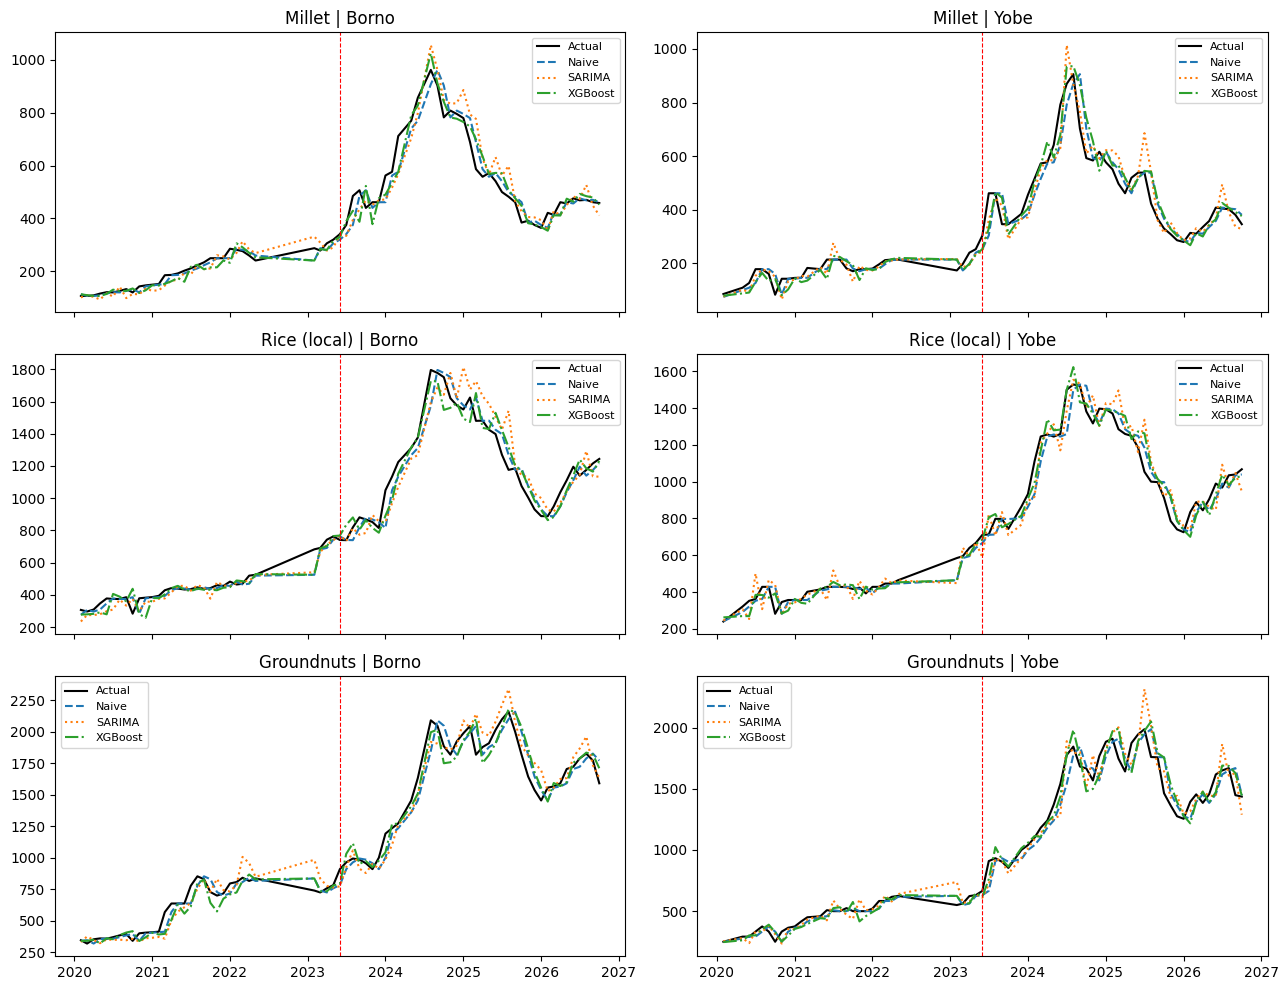

In [13]:
# Plotting actual prices against 1-month-ahead forecasts
f1 = forecasts[forecasts['h'] == 1].sort_values('target')
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)

for i, crop in enumerate(['Millet', 'Rice (local)', 'Groundnuts']):
    for j, state in enumerate(['Borno', 'Yobe']):
        ax = axes[i, j]
        d = f1[(f1['commodity'] == crop) & (f1['state'] == state)]
        ax.plot(d['target'], d['actual'], color='black', label='Actual')
        ax.plot(d['target'], d['naive'], linestyle='--', label='Naive')
        ax.plot(d['target'], d['sarima'], linestyle=':', label='SARIMA')
        ax.plot(d['target'], d['xgboost'], linestyle='-.', label='XGBoost')
        ax.axvline(BREAK, color='red', linestyle='--', linewidth=0.8)
        ax.set_title(f'{crop} | {state}')
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

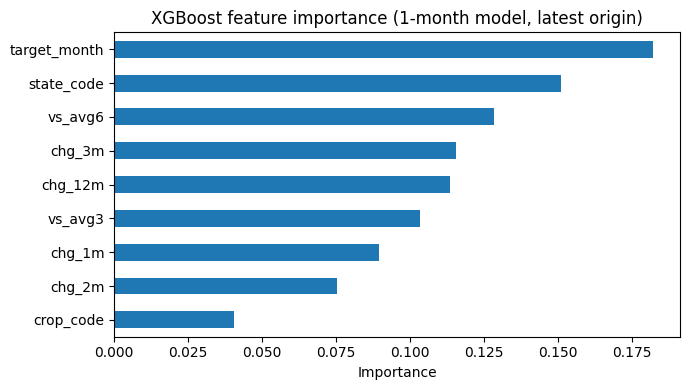

In [14]:
# Plotting which features the 1-month XGBoost model relied on most
imp = pd.Series(importances).sort_values()
imp.plot(kind='barh', figsize=(7, 4))
plt.title('XGBoost feature importance (1-month model, latest origin)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

### 6. Forecasting beyond the data
Training on all the data and forecasting the 3 months after the last observed month (October 2026).
Nothing exists yet to score these against, so each comes with the typical error from the backtest.

In [15]:
# Forecasting beyond the data: the 3 months after the last observed month
last_date = df['date'].max()

# XGBoost: training on all past examples, then predicting from the last month
xgb_future = {}
for h in HORIZONS:
    tmp = feat.copy()
    tmp['target_month'] = (tmp['date'] + pd.DateOffset(months=h)).dt.month
    train = tmp[(tmp['date'] + pd.DateOffset(months=h) <= last_date) & tmp[f'y{h}'].notna()]
    now = tmp[tmp['date'] == last_date]
    model = XGBRegressor(n_estimators=150, max_depth=3, learning_rate=0.05,
                         subsample=0.8, random_state=0, n_jobs=1)
    model.fit(train[FEATURES], train[f'y{h}'])
    change = model.predict(now[FEATURES])
    for s, c, p, ch in zip(now['state'], now['commodity'], now['price'], change):
        xgb_future[(s, c, h)] = p * np.exp(ch)

# Naive and SARIMA forecasts for each series
rows = []
for key, price in series.items():
    last_known = price.dropna().iloc[-1]
    fit = SARIMAX(np.log(price), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12),
                  enforce_stationarity=True, enforce_invertibility=True).fit(disp=False, maxiter=100)
    sarima_future = np.exp(fit.forecast(max(HORIZONS)).values)
    for h in HORIZONS:
        rows.append({'state': key[0], 'commodity': key[1],
                     'target': (last_date + pd.DateOffset(months=h)).strftime('%Y-%m'),
                     'h': h, 'last_price': last_known, 'naive': last_known,
                     'sarima': sarima_future[h - 1], 'xgboost': xgb_future[(key[0], key[1], h)]})

outlook = pd.DataFrame(rows)
outlook.round(0)

,state,commodity,target,h,last_price,naive,sarima,xgboost
0,Borno,Groundnuts,2026-11,1,1591.0,1591.0,1545.0,1559.0
1,Borno,Groundnuts,2026-12,2,1591.0,1591.0,1551.0,1580.0
2,Borno,Groundnuts,2027-01,3,1591.0,1591.0,1595.0,1525.0
3,Borno,Millet,2026-11,1,459.0,459.0,472.0,463.0
4,Borno,Millet,2026-12,2,459.0,459.0,478.0,442.0
5,Borno,Millet,2027-01,3,459.0,459.0,487.0,468.0
6,Borno,Rice (local),2026-11,1,1244.0,1244.0,1230.0,1242.0
7,Borno,Rice (local),2026-12,2,1244.0,1244.0,1202.0,1253.0
8,Borno,Rice (local),2027-01,3,1244.0,1244.0,1239.0,1330.0
9,Yobe,Groundnuts,2026-11,1,1436.0,1436.0,1454.0,1426.0


In [16]:
# Typical error (MAPE) from the backtest, using the period from mid-2023
err = results[results['period'] == 'from 2023-06'].pivot_table(index='h', columns='model', values='MAPE')

# Adding a typical error range around each forecast
for m in ['naive', 'sarima', 'xgboost']:
    pct = outlook['h'].map(err[m]) / 100
    outlook[m + '_low'] = outlook[m] * (1 - pct)
    outlook[m + '_high'] = outlook[m] * (1 + pct)

# Saving the outlook for Notebook 5
outlook.to_csv('outlook_forecasts.csv', index=False)
print(outlook.shape)
outlook[['state', 'commodity', 'target', 'naive', 'naive_low', 'naive_high']].round(0)

(18, 14)


,state,commodity,target,naive,naive_low,naive_high
0,Borno,Groundnuts,2026-11,1591.0,1482.0,1699.0
1,Borno,Groundnuts,2026-12,1591.0,1399.0,1783.0
2,Borno,Groundnuts,2027-01,1591.0,1336.0,1846.0
3,Borno,Millet,2026-11,459.0,427.0,490.0
4,Borno,Millet,2026-12,459.0,403.0,514.0
5,Borno,Millet,2027-01,459.0,385.0,532.0
6,Borno,Rice (local),2026-11,1244.0,1159.0,1329.0
7,Borno,Rice (local),2026-12,1244.0,1094.0,1394.0
8,Borno,Rice (local),2027-01,1244.0,1044.0,1444.0
9,Yobe,Groundnuts,2026-11,1436.0,1338.0,1534.0


## Forecasting findings

- Setup: rolling-origin evaluation (each model refit at every origin using only past data), horizons of 1-3 months, first origin January 2020, scored only on months with a real (not interpolated) price: 1,245 forecasts across 6 series. Models: naive, seasonal naive, SARIMA(1,1,1)(0,1,1,12) and XGBoost (predicting the % change from the latest price).
- Overall average error (MAPE) at 1, 2 and 3 months ahead: naive 6.9%, 11.5%, 15.1%; XGBoost 8.2%, 13.0%, 16.5%; SARIMA 9.4%, 13.3%, 16.4%; seasonal naive 29.6%, 30.5%, 30.9%.
- The naive baseline (repeating the latest price) was the most accurate overall at every horizon, and clearly better before mid-2023.
- Since mid-2023, XGBoost was about level with naive at 1 month (6.9% vs 6.8%) and slightly better at 2 and 3 months (11.4% vs 12.0%; 14.9% vs 16.1%; in naira, 112 vs 118 and 147 vs 156 per kg). No significance test was run, so differences are described as small, not established.
- SARIMA was never the best model.
- Seasonal naive was weakest because prices rise or fall sharply from year to year, so last year's price is rarely a good guide.
- Errors grow with the horizon: 3-month forecasts are about twice as far off as 1-month forecasts. In naira terms errors are larger after mid-2023 because prices are much higher.
- Interpretation: over 1-3 months, prices in this dataset behave close to a random walk, so the latest price is hard to beat; machine learning adds a little only in the volatile post-2023 period at longer horizons.
- Outlook (November 2026 to January 2027): the models agree that prices are likely to stay near their October 2026 level, with no strong signal of a large rise or fall. Each forecast is shown with the typical backtest error.
- Limitations: about 700 monthly observations in total; XGBoost not tuned; 135 seasonal naive forecasts fell back to naive (last year's price missing) and 36 XGBoost forecasts used naive (origins inside the 2022 data hole); interpolated months are used as model inputs but never scored.

Outputs: forecasts_all_models.csv, model_accuracy_results.csv, outlook_forecasts.csv